# Inspecting `vgrid_daily` — the lag-1 demand HC-MAE winner (user 2024 split)

Headline: Δ_HC = −6.46, **95 % paired CI (−9.7, −3.4)**, day-level Wilcoxon **Holm-p < 0.001**, win-rate 53.4 % vs lag-1 baseline on **366 days** in 2024.

This is the *only* realised model with a statistically-significant win under HC-MAE on the user-specified 2024 test window. The rest of the notebook drills into this single model: example curves, Δ distribution, per-month, per-interval, per-weekday, and a hard-case decile breakdown.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from aemo_curves.metrics.hc_mae import curve_hc_mae_distance

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

REPO = Path('..').resolve()
RESULTS_CSV = REPO / 'experiments' / 'vgrid_1d_demand' / 'results.csv'
BEST_RUN = 'user2024__rolling_daily_vgrid_ridge'
BASE_RUN = 'user2024__baseline_lag1_demand'

summary = pd.read_csv(RESULTS_CSV).sort_values('delta_hc_mean').reset_index(drop=True)
print('Leaderboard under HC-MAE (lower delta_hc_mean = better):\n')
show_cols = ['run', 'embedding', 'hc_mae_mean', 'delta_hc_mean',
             'delta_hc_ci_lo', 'delta_hc_ci_hi', 'win_rate',
             'wilcoxon_p_holm']
print(summary[show_cols].round(3).to_string(index=False))

Leaderboard under HC-MAE (lower delta_hc_mean = better):

                run embedding  hc_mae_mean  delta_hc_mean  delta_hc_ci_lo  delta_hc_ci_hi  win_rate  wilcoxon_p_holm
 vgrid_daily_oracle    v_grid       24.651        -90.682         -96.001         -85.684     0.905              NaN
vgrid_static_oracle    v_grid       28.286        -87.047         -92.254         -81.943     0.886              NaN
        vgrid_daily    v_grid      108.875         -6.458          -9.713          -3.365     0.534            0.000
       vgrid_static    v_grid      114.395         -0.938          -4.515           2.232     0.483            0.869
      lag1_baseline         —      115.333          0.000           0.000           0.000       NaN              NaN
      interp_static    interp      141.704         26.371          20.416          31.885     0.383            1.000
       interp_daily    interp      143.224         27.891          21.936          33.396     0.385            1.000


## Load best model + baseline predictions, score per row

In [2]:
MLRUNS = REPO / 'mlruns'
def find_run(name):
    for t in MLRUNS.glob('*/*/tags/experiment_name'):
        if t.read_text().strip() == name:
            return t.parent.parent
    raise FileNotFoundError(name)

best = pd.read_pickle(find_run(BEST_RUN) / 'artifacts' / 'result' / 'predictions.pkl')
base = pd.read_pickle(find_run(BASE_RUN) / 'artifacts' / 'result' / 'predictions.pkl')
for df in (best, base):
    df['Trading Date'] = pd.to_datetime(df['Trading Date'])
print(f'best ({BEST_RUN}): {len(best):,} rows  ·  '
      f'{best["Trading Date"].min().date()} → {best["Trading Date"].max().date()}')
print(f'baseline ({BASE_RUN}): {len(base):,} rows')

def _row(args):
    return curve_hc_mae_distance(args[0], args[1], args[2], args[3])

for df, lab in [(best, 'best'), (base, 'baseline')]:
    args = list(zip(df['true_curve_qty'], df['true_curve_price'],
                    df['pred_curve_qty'], df['pred_curve_price']))
    df['hc_mae'] = Parallel(n_jobs=-1)(delayed(_row)(a) for a in args)
    print(f'{lab}: HC-MAE mean={df["hc_mae"].mean():.2f}  median={df["hc_mae"].median():.2f}')

key = ['Trading Date', 'Interval Number']
merged = best.merge(
    base[key + ['hc_mae', 'pred_curve_qty', 'pred_curve_price']].rename(
        columns={'hc_mae': 'baseline_hc_mae',
                 'pred_curve_qty': 'base_curve_qty',
                 'pred_curve_price': 'base_curve_price'}),
    on=key, how='inner')
merged['delta_hc'] = merged['hc_mae'] - merged['baseline_hc_mae']
merged['win'] = merged['delta_hc'] < 0
merged['month'] = merged['Trading Date'].dt.to_period('M').astype(str)
merged['dow'] = merged['Trading Date'].dt.dayofweek
print(f'\nmerged: {len(merged):,} rows on {merged["Trading Date"].nunique()} days  ·  '
      f'mean Δ={merged["delta_hc"].mean():+.3f}  ·  win-rate={merged["win"].mean():.4f}')

best (user2024__rolling_daily_vgrid_ridge): 17,568 rows  ·  2024-01-01 → 2024-12-31
baseline (user2024__baseline_lag1_demand): 17,568 rows


best: HC-MAE mean=108.88  median=87.33


baseline: HC-MAE mean=115.33  median=90.10

merged: 17,568 rows on 366 days  ·  mean Δ=-6.458  ·  win-rate=0.5340


## Distribution of per-row HC-MAE, scatter, and per-month bar

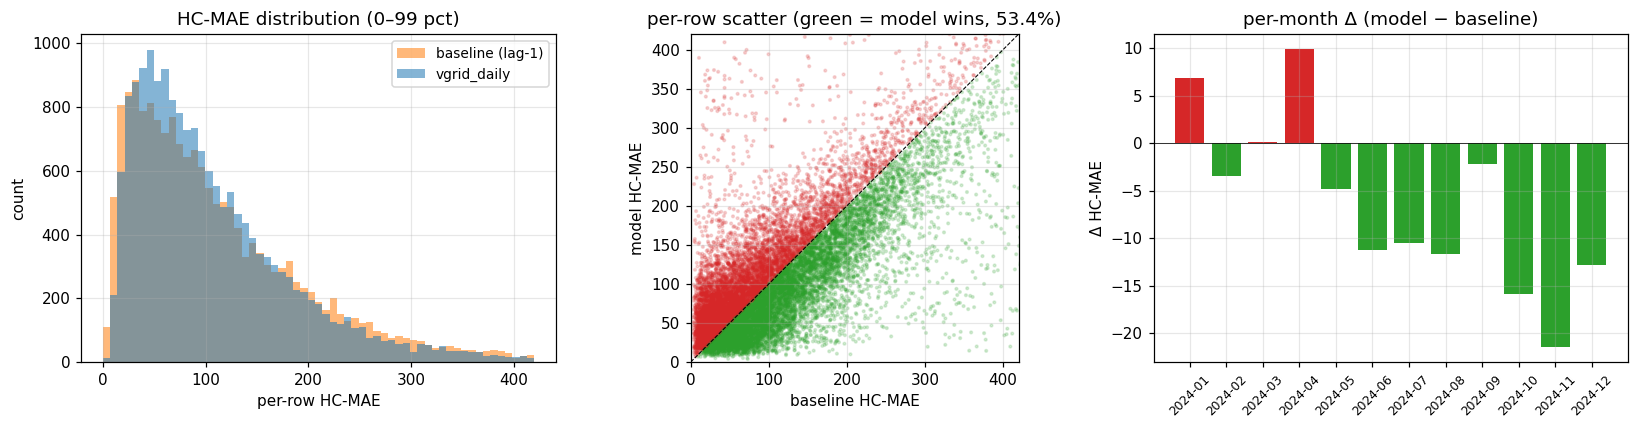


per-month summary:
  month  delta_mean  win_rate
2024-01       6.816     0.448
2024-02      -3.508     0.511
2024-03       0.166     0.452
2024-04       9.899     0.398
2024-05      -4.793     0.544
2024-06     -11.240     0.565
2024-07     -10.490     0.589
2024-08     -11.699     0.607
2024-09      -2.169     0.508
2024-10     -15.916     0.575
2024-11     -21.467     0.616
2024-12     -12.874     0.593


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(0, np.quantile(np.r_[merged['hc_mae'], merged['baseline_hc_mae']], 0.99), 60)
axes[0].hist(merged['baseline_hc_mae'], bins=bins, alpha=0.55, label='baseline (lag-1)', color='C1')
axes[0].hist(merged['hc_mae'], bins=bins, alpha=0.55, label='vgrid_daily', color='C0')
axes[0].set_xlabel('per-row HC-MAE'); axes[0].set_ylabel('count'); axes[0].legend(fontsize=9)
axes[0].set_title('HC-MAE distribution (0–99 pct)')

axes[1].scatter(merged['baseline_hc_mae'], merged['hc_mae'], s=3, alpha=0.18,
                c=np.where(merged['win'], 'C2', 'C3'))
lim = float(np.quantile(np.r_[merged['hc_mae'], merged['baseline_hc_mae']], 0.99))
axes[1].plot([0, lim], [0, lim], 'k--', lw=0.7)
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim); axes[1].set_aspect('equal')
axes[1].set_xlabel('baseline HC-MAE'); axes[1].set_ylabel('model HC-MAE')
axes[1].set_title(f'per-row scatter (green = model wins, {merged["win"].mean():.1%})')

monthly = merged.groupby('month').agg(delta_mean=('delta_hc', 'mean'),
                                       win_rate=('win', 'mean')).reset_index()
x = np.arange(len(monthly))
axes[2].bar(x, monthly['delta_mean'],
            color=np.where(monthly['delta_mean'] < 0, 'C2', 'C3'))
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_xticks(x); axes[2].set_xticklabels(monthly['month'], rotation=45, fontsize=8)
axes[2].set_ylabel('Δ HC-MAE'); axes[2].set_title('per-month Δ (model − baseline)')
plt.tight_layout(); plt.show()

print('\nper-month summary:')
print(monthly.round(3).to_string(index=False))

## Detailed Δ analysis — distribution, CDFs, cumulative gain

Δ HC-MAE quantiles  p05=-95.85  p25=-35.48  p50=-3.74  p75=+25.20  p95=+77.46
  mean Δ = -6.458  ·  trimmed5%-mean = -5.129


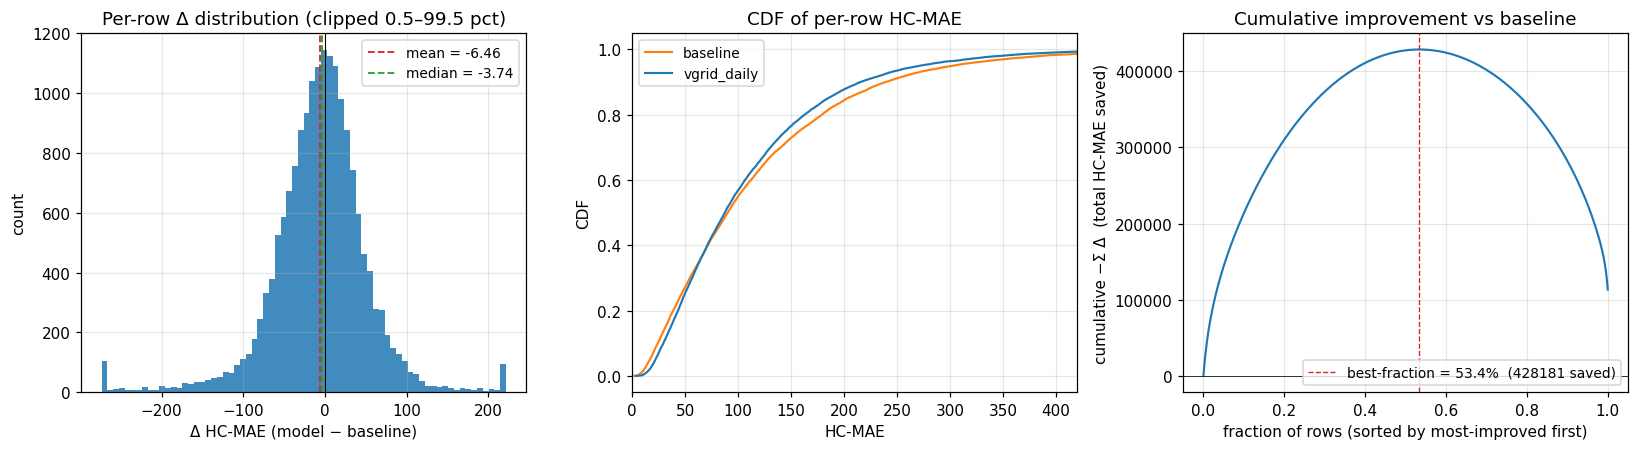

In [4]:
d = merged['delta_hc'].to_numpy()
qs = np.quantile(d, [0.05, 0.25, 0.5, 0.75, 0.95])
print(f'Δ HC-MAE quantiles  p05={qs[0]:+.2f}  p25={qs[1]:+.2f}  p50={qs[2]:+.2f}  '
      f'p75={qs[3]:+.2f}  p95={qs[4]:+.2f}')
print(f'  mean Δ = {d.mean():+.3f}  ·  trimmed5%-mean = {d[(d>=qs[0])&(d<=qs[4])].mean():+.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
lo, hi = np.quantile(d, [0.005, 0.995])
axes[0].hist(d.clip(lo, hi), bins=70, color='C0', alpha=0.85)
axes[0].axvline(0, color='k', lw=0.7)
axes[0].axvline(d.mean(), color='C3', ls='--', lw=1.2, label=f'mean = {d.mean():+.2f}')
axes[0].axvline(np.median(d), color='C2', ls='--', lw=1.2, label=f'median = {np.median(d):+.2f}')
axes[0].set_xlabel('Δ HC-MAE (model − baseline)'); axes[0].set_ylabel('count')
axes[0].set_title('Per-row Δ distribution (clipped 0.5–99.5 pct)')
axes[0].legend(fontsize=9)

mb = merged['baseline_hc_mae'].to_numpy(); mm = merged['hc_mae'].to_numpy()
y = np.arange(1, len(mb) + 1) / len(mb)
axes[1].plot(np.sort(mb), y, color='C1', lw=1.4, label='baseline')
axes[1].plot(np.sort(mm), y, color='C0', lw=1.4, label='vgrid_daily')
axes[1].set_xlabel('HC-MAE'); axes[1].set_ylabel('CDF')
axes[1].set_xlim(0, np.quantile(np.r_[mb, mm], 0.99))
axes[1].set_title('CDF of per-row HC-MAE')
axes[1].legend(fontsize=9)

order = np.argsort(d)
cumgain = -np.cumsum(d[order])
frac = np.arange(1, len(d) + 1) / len(d)
axes[2].plot(frac, cumgain, lw=1.4, color='C0')
axes[2].axhline(0, color='k', lw=0.5)
axes[2].set_xlabel('fraction of rows (sorted by most-improved first)')
axes[2].set_ylabel('cumulative −Σ Δ  (total HC-MAE saved)')
axes[2].set_title('Cumulative improvement vs baseline')
imax = int(np.argmax(cumgain))
axes[2].axvline(frac[imax], color='C3', ls='--', lw=0.9,
                label=f'best-fraction = {frac[imax]:.1%}  ({cumgain[imax]:.0f} saved)')
axes[2].legend(fontsize=9)
plt.tight_layout(); plt.show()

## Per-interval, per-weekday, and interval×weekday heatmap

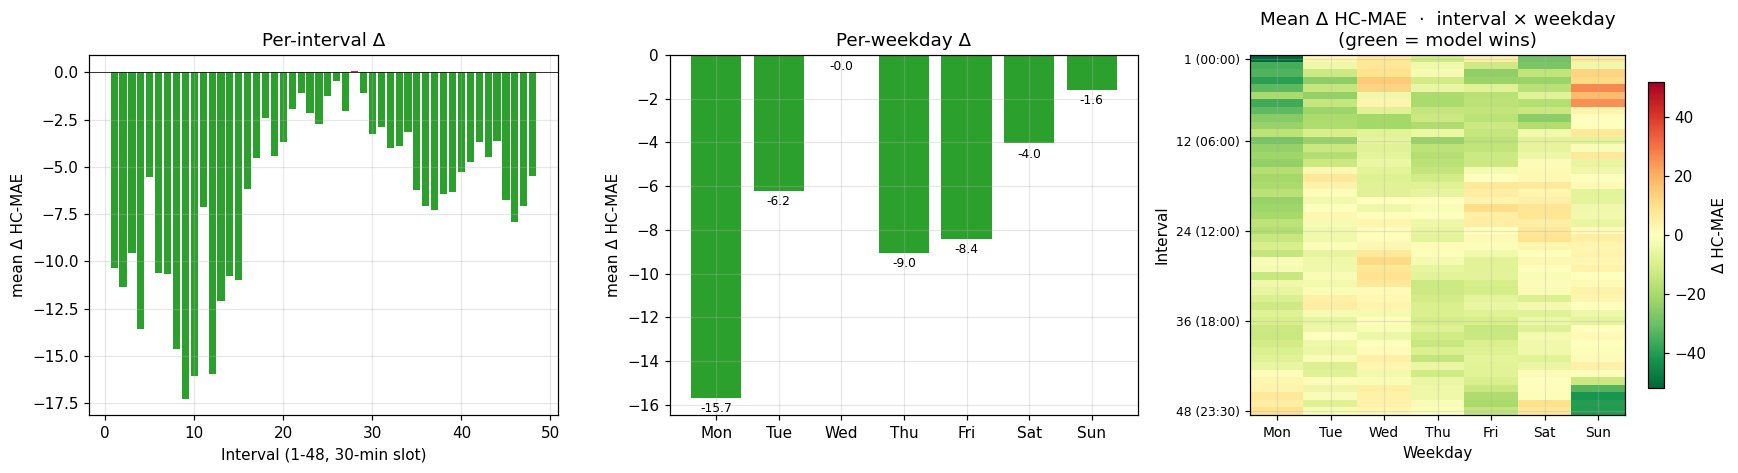


Weakest weekday: Wed (Δ=-0.05)
Strongest weekday: Mon (Δ=-15.70)


In [5]:
dow_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_int = merged.groupby('Interval Number').agg(delta=('delta_hc', 'mean'),
                                                 win=('win', 'mean')).reset_index()
by_dow = merged.groupby('dow').agg(delta=('delta_hc', 'mean'),
                                    win=('win', 'mean')).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].bar(by_int['Interval Number'], by_int['delta'],
            color=np.where(by_int['delta'] < 0, 'C2', 'C3'))
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_xlabel('Interval (1-48, 30-min slot)'); axes[0].set_ylabel('mean Δ HC-MAE')
axes[0].set_title('Per-interval Δ')

axes[1].bar(np.arange(7), by_dow['delta'],
            color=np.where(by_dow['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(dow_labels)
axes[1].set_ylabel('mean Δ HC-MAE')
axes[1].set_title('Per-weekday Δ')
for i, v in enumerate(by_dow['delta']):
    axes[1].text(i, v - 0.2, f'{v:+.1f}', ha='center', va='top', fontsize=8)

pivot = (merged.groupby(['Interval Number', 'dow'])['delta_hc']
         .mean().unstack('dow'))
vmax = float(np.nanmax(np.abs(pivot.values)))
im = axes[2].imshow(pivot.values, aspect='auto', cmap='RdYlGn_r', vmin=-vmax, vmax=vmax)
axes[2].set_yticks([0, 11, 23, 35, 47])
axes[2].set_yticklabels(['1 (00:00)', '12 (06:00)', '24 (12:00)', '36 (18:00)', '48 (23:30)'], fontsize=8)
axes[2].set_xticks(range(7)); axes[2].set_xticklabels(dow_labels, fontsize=9)
axes[2].set_ylabel('Interval'); axes[2].set_xlabel('Weekday')
axes[2].set_title('Mean Δ HC-MAE  ·  interval × weekday\n(green = model wins)')
fig.colorbar(im, ax=axes[2], shrink=0.85, label='Δ HC-MAE')
plt.tight_layout(); plt.show()

worst_dow = int(by_dow['delta'].idxmax()); best_dow = int(by_dow['delta'].idxmin())
print(f'\nWeakest weekday: {dow_labels[by_dow.iloc[worst_dow, 0]]} '
      f'(Δ={by_dow.iloc[worst_dow, 1]:+.2f})')
print(f'Strongest weekday: {dow_labels[by_dow.iloc[best_dow, 0]]} '
      f'(Δ={by_dow.iloc[best_dow, 1]:+.2f})')

## Performance vs baseline difficulty — does the model help on hard cases?

Stratify by the baseline's per-row HC-MAE (= how hard the test row was for lag-1), then look at where the model lifts.

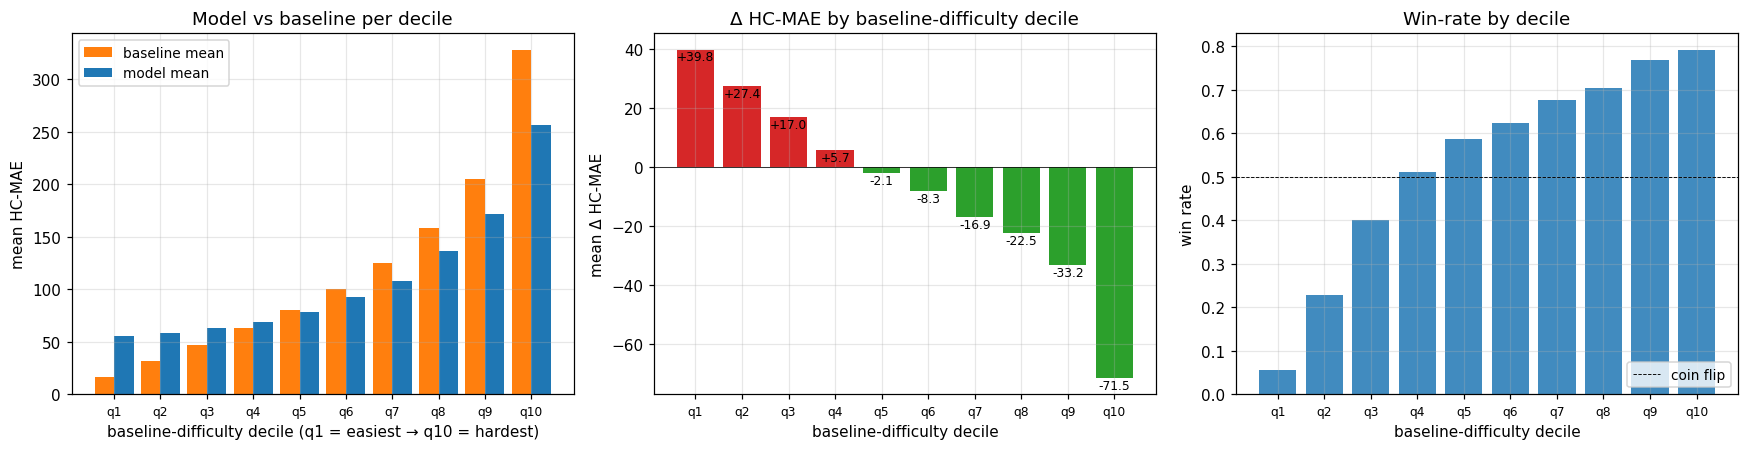


Per-difficulty decile summary:
 baseline_q  baseline_mean  model_mean   delta   win    n
          0         16.045      55.815  39.770 0.055 1757
          1         31.301      58.682  27.380 0.228 1757
          2         46.412      63.421  17.009 0.401 1757
          3         62.866      68.562   5.697 0.510 1756
          4         80.462      78.359  -2.104 0.587 1757
          5        100.352      92.090  -8.262 0.623 1757
          6        124.947     108.066 -16.882 0.677 1756
          7        158.448     135.980 -22.468 0.703 1757
          8        205.096     171.897 -33.200 0.767 1757
          9        327.373     255.856 -71.517 0.790 1757


In [6]:
n_bins = 10
merged['baseline_q'] = pd.qcut(merged['baseline_hc_mae'], n_bins, labels=False, duplicates='drop')
by_q = merged.groupby('baseline_q').agg(
    baseline_mean=('baseline_hc_mae', 'mean'),
    model_mean=('hc_mae', 'mean'),
    delta=('delta_hc', 'mean'),
    win=('win', 'mean'),
    n=('hc_mae', 'size'),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(by_q)); w = 0.42
axes[0].bar(x - w/2, by_q['baseline_mean'], w, color='C1', label='baseline mean')
axes[0].bar(x + w/2, by_q['model_mean'], w, color='C0', label='model mean')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[0].set_xlabel('baseline-difficulty decile (q1 = easiest → q10 = hardest)')
axes[0].set_ylabel('mean HC-MAE'); axes[0].set_title('Model vs baseline per decile')
axes[0].legend(fontsize=9)

axes[1].bar(x, by_q['delta'], color=np.where(by_q['delta'] < 0, 'C2', 'C3'))
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(x); axes[1].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[1].set_xlabel('baseline-difficulty decile'); axes[1].set_ylabel('mean Δ HC-MAE')
axes[1].set_title('Δ HC-MAE by baseline-difficulty decile')
for i, v in enumerate(by_q['delta']):
    axes[1].text(i, v - 0.3, f'{v:+.1f}', ha='center', va='top', fontsize=8)

axes[2].bar(x, by_q['win'], color='C0', alpha=0.85)
axes[2].axhline(0.5, color='k', lw=0.6, ls='--', label='coin flip')
axes[2].set_xticks(x); axes[2].set_xticklabels([f'q{i+1}' for i in x], fontsize=8)
axes[2].set_xlabel('baseline-difficulty decile'); axes[2].set_ylabel('win rate')
axes[2].set_title('Win-rate by decile')
axes[2].legend(fontsize=9, loc='lower right')
plt.tight_layout(); plt.show()

print('\nPer-difficulty decile summary:')
print(by_q.round(3).to_string(index=False))

## Per-month detail — mean, median, IQR band, win-rate, full Δ boxplot

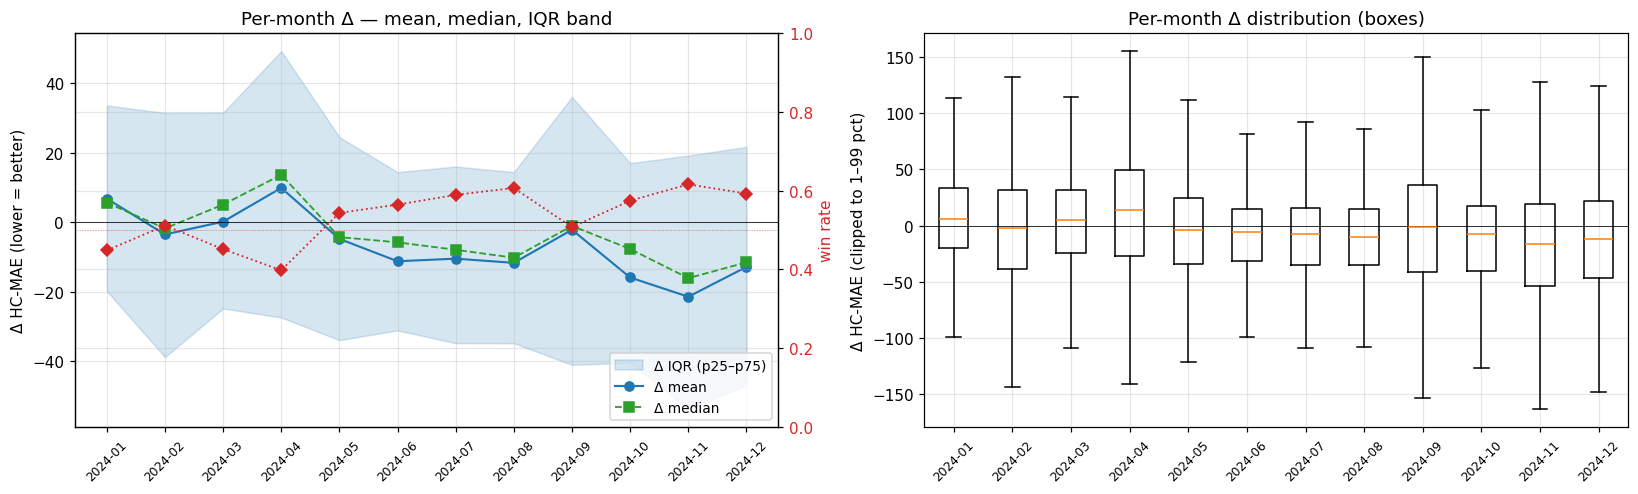


  month    n  delta_mean  delta_median  delta_p25  delta_p75  win_rate
2024-01 1488        6.82          5.63     -19.81      33.64      0.45
2024-02 1392       -3.51         -1.77     -38.85      31.51      0.51
2024-03 1488        0.17          5.09     -24.84      31.55      0.45
2024-04 1440        9.90         13.67     -27.45      49.33      0.40
2024-05 1488       -4.79         -4.28     -33.96      24.55      0.54
2024-06 1440      -11.24         -5.79     -31.16      14.44      0.56
2024-07 1488      -10.49         -7.93     -34.83      16.05      0.59
2024-08 1488      -11.70        -10.23     -34.84      14.45      0.61
2024-09 1440       -2.17         -1.06     -41.09      36.12      0.51
2024-10 1488      -15.92         -7.70     -40.48      17.04      0.57
2024-11 1440      -21.47        -16.10     -53.83      19.19      0.62
2024-12 1488      -12.87        -11.57     -47.06      21.73      0.59


In [7]:
monthly_full = merged.groupby('month').agg(
    n=('delta_hc', 'size'),
    delta_mean=('delta_hc', 'mean'),
    delta_median=('delta_hc', 'median'),
    delta_p25=('delta_hc', lambda x: x.quantile(0.25)),
    delta_p75=('delta_hc', lambda x: x.quantile(0.75)),
    win_rate=('win', 'mean'),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(monthly_full))

ax = axes[0]
ax.fill_between(x, monthly_full['delta_p25'], monthly_full['delta_p75'],
                color='C0', alpha=0.18, label='Δ IQR (p25–p75)')
ax.plot(x, monthly_full['delta_mean'], 'o-', color='C0', lw=1.4, label='Δ mean')
ax.plot(x, monthly_full['delta_median'], 's--', color='C2', lw=1.2, label='Δ median')
ax.axhline(0, color='k', lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(monthly_full['month'], rotation=45, fontsize=8)
ax.set_ylabel('Δ HC-MAE (lower = better)')
ax.set_title('Per-month Δ — mean, median, IQR band')
ax.legend(loc='lower right', fontsize=9)
ax2 = ax.twinx()
ax2.plot(x, monthly_full['win_rate'], 'D:', color='C3', lw=1.2)
ax2.axhline(0.5, color='C3', lw=0.4, ls=':')
ax2.set_ylabel('win rate', color='C3'); ax2.set_ylim(0, 1.0)
ax2.tick_params(axis='y', labelcolor='C3')

data_by_month = [merged[merged['month'] == m]['delta_hc'].clip(
                    lower=np.quantile(merged['delta_hc'], 0.01),
                    upper=np.quantile(merged['delta_hc'], 0.99))
                 for m in monthly_full['month']]
axes[1].boxplot(data_by_month, showfliers=False)
axes[1].axhline(0, color='k', lw=0.5)
axes[1].set_xticks(np.arange(1, len(monthly_full) + 1))
axes[1].set_xticklabels(monthly_full['month'], rotation=45, fontsize=8)
axes[1].set_ylabel('Δ HC-MAE (clipped to 1–99 pct)')
axes[1].set_title('Per-month Δ distribution (boxes)')
plt.tight_layout(); plt.show()

print()
print(monthly_full.round(2).to_string(index=False))

## Four random examples — actual / model / baseline

Black = actual. Blue = `vgrid_daily`. Orange = lag-1 baseline. Re-run the cell for a fresh sample.

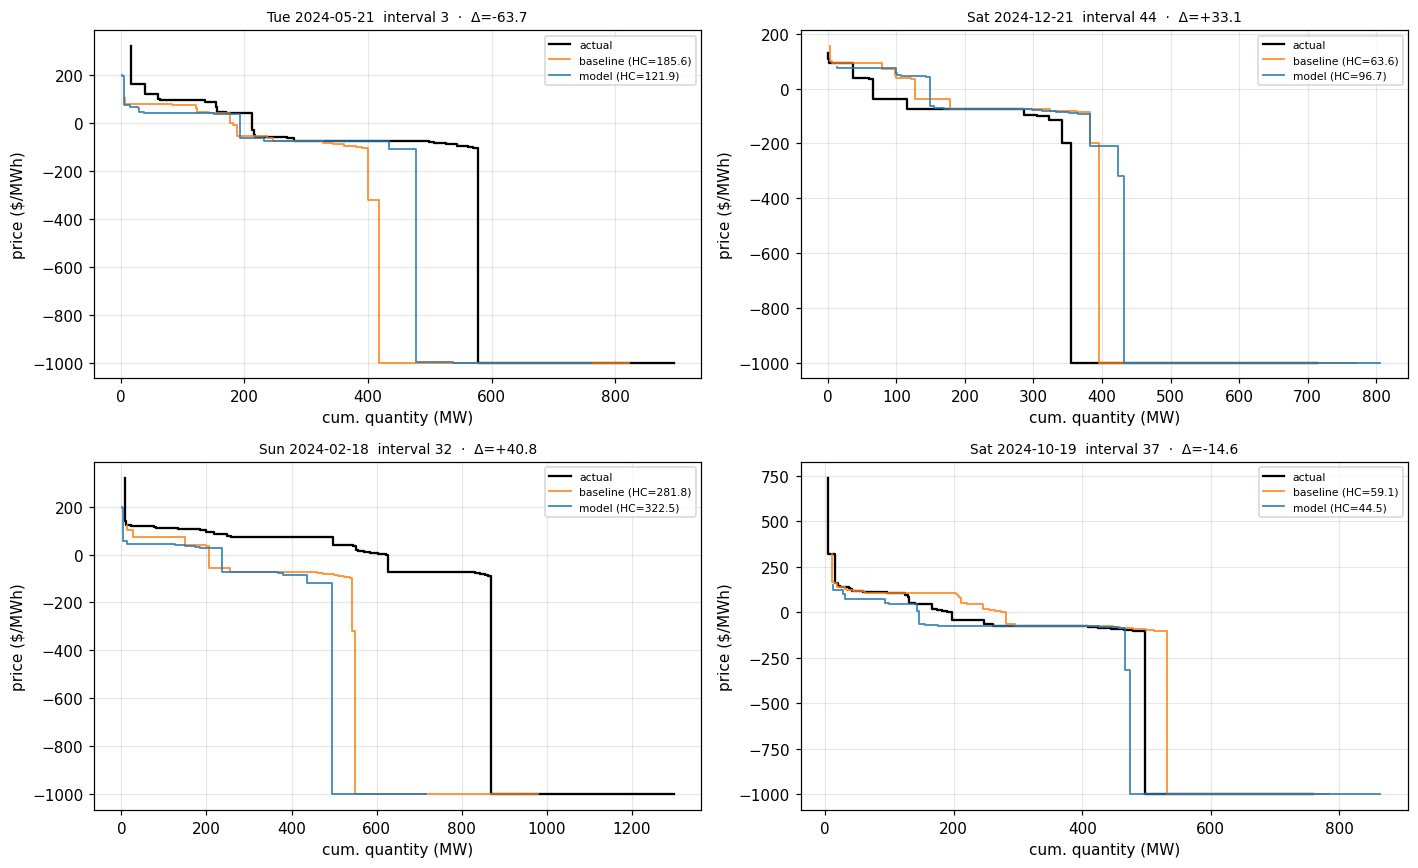

In [8]:
def plot_row(ax, r, title):
    ax.step(r['true_curve_qty'], r['true_curve_price'], where='pre', color='black', lw=1.5, label='actual')
    ax.step(r['base_curve_qty'], r['base_curve_price'], where='pre', color='C1', lw=1.2, alpha=0.85,
            label=f'baseline (HC={r["baseline_hc_mae"]:.1f})')
    ax.step(r['pred_curve_qty'], r['pred_curve_price'], where='pre', color='C0', lw=1.2, alpha=0.85,
            label=f'model (HC={r["hc_mae"]:.1f})')
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('cum. quantity (MW)'); ax.set_ylabel('price ($/MWh)')
    ax.legend(fontsize=7, loc='best')

rng = np.random.default_rng()
pick = merged.sample(4, random_state=rng.integers(1_000_000)).reset_index(drop=True)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (_, r) in zip(axes.flat, pick.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(ax, r, f'{date_str}  interval {int(r["Interval Number"])}  ·  Δ={r["delta_hc"]:+.1f}')
plt.tight_layout(); plt.show()

## Three biggest wins (model ≫ baseline) and three biggest regressions

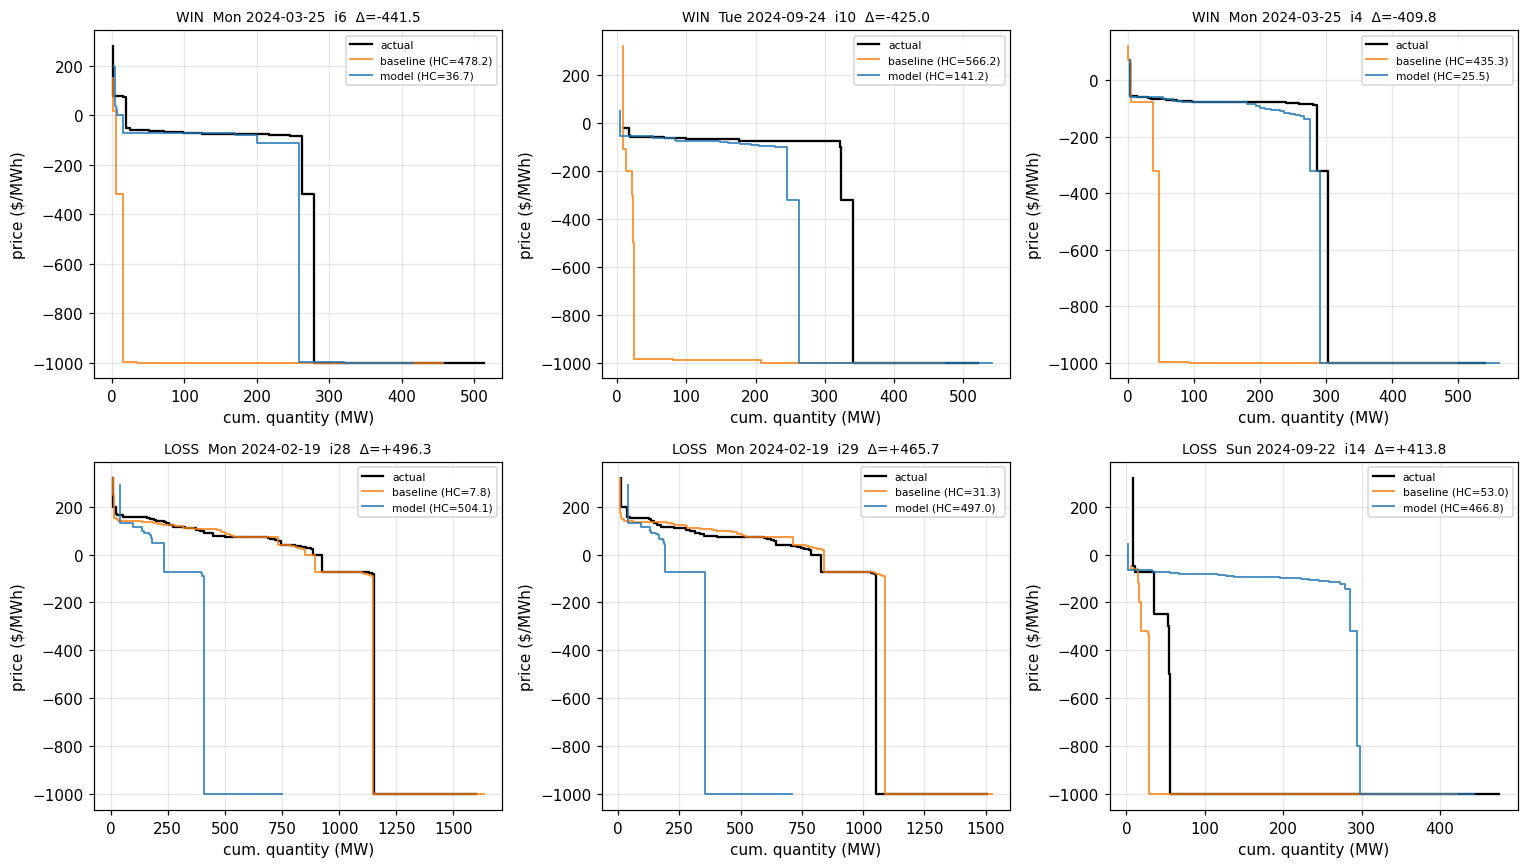

In [9]:
wins = merged.nsmallest(3, 'delta_hc').reset_index(drop=True)
losses = merged.nlargest(3, 'delta_hc').reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, (_, r) in enumerate(wins.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(axes[0, col], r, f'WIN  {date_str}  i{int(r["Interval Number"])}  Δ={r["delta_hc"]:+.1f}')
for col, (_, r) in enumerate(losses.iterrows()):
    date_str = pd.Timestamp(r['Trading Date']).strftime('%a %Y-%m-%d')
    plot_row(axes[1, col], r, f'LOSS  {date_str}  i{int(r["Interval Number"])}  Δ={r["delta_hc"]:+.1f}')
plt.tight_layout(); plt.show()